In [ ]:
#!pip install pyswarms

In [1]:
# Import modules
import numpy as np
import matplotlib.pyplot as plt
import numpy as np

In [3]:
swarm_size = 50
dim = 7        # Dimension of X
epsilon = 1.0
options = {'c1': 1.5, 'c2':1.5, 'w':0.5}

lim1 = np.deg2rad(170)
lim2 = np.deg2rad(120)
lim3 = np.deg2rad(170)
lim4 = np.deg2rad(120)
lim5 = np.deg2rad(170)
lim6 = np.deg2rad(120)
lim7 = np.deg2rad(175)

constraints = (np.array([-lim1 , -lim2 , -lim3 , -lim4 , -lim5 , -lim6, -lim7]),
               np.array([ lim1  , lim2 ,  lim3 ,  lim4 ,  lim5 ,  lim6,  lim7]))

d2 = d4 = d4 = d6 = 0.03
d1 = 0.34
d3 = 0.4
d5 = 0.4
d7 = 0.126

In [4]:
def getTransformMatrix(theta, d, a, alpha):
    T = np.array([[np.cos(theta) , -np.sin(theta)*np.cos(alpha) ,  np.sin(theta)*np.sin(alpha) , a*np.cos(theta)],
                  [np.sin(theta) ,  np.cos(theta)*np.cos(alpha) , -np.cos(theta)*np.sin(alpha) , a*np.sin(theta)],
                  [0             ,  np.sin(alpha)               ,  np.cos(alpha)               , d              ],
                  [0             ,  0                           ,  0                           , 1              ]
                 ])
    return T

def get_end_tip_position(params):
    # Create the transformation matrices for the respective joints
    t_00 = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
    t_01 = getTransformMatrix(params[0] , d1  , 0 , -np.pi/2)
    t_12 = getTransformMatrix(params[1] , d2  , 0 ,  np.pi/2)
    t_23 = getTransformMatrix(params[2] , d3  , 0 ,  np.pi/2)
    t_34 = getTransformMatrix(params[3] , d4  , 0 , -np.pi/2)
    t_45 = getTransformMatrix(params[4] , d5  , 0 , -np.pi/2)
    t_56 = getTransformMatrix(params[5] , d6  , 0 ,  np.pi/2)
    t_67 = getTransformMatrix(params[6] , d7  , 0 ,        0)

    # Get the overall transformation matrix
    end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)

    # The coordinates of the end tip are the 3 upper entries in the 4th column
    pos = np.array([end_tip_m[0,3],end_tip_m[1,3],end_tip_m[2,3]])
    return pos

def get_nth_position(params,n):
    # Create the transformation matrices for the respective joints
    t_00 = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
    t_01 = getTransformMatrix(params[0] , d1  , 0 , -np.pi/2)
    t_12 = getTransformMatrix(params[1] , d2  , 0 ,  np.pi/2)
    t_23 = getTransformMatrix(params[2] , d3  , 0 ,  np.pi/2)
    t_34 = getTransformMatrix(params[3] , d4  , 0 , -np.pi/2)
    t_45 = getTransformMatrix(params[4] , d5  , 0 , -np.pi/2)
    t_56 = getTransformMatrix(params[5] , d6  , 0 ,  np.pi/2)
    t_67 = getTransformMatrix(params[6] , d7  , 0 ,        0)

    if n==0:
        end_tip_m = t_00#.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==1:
        end_tip_m = t_00.dot(t_01)#.dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==2:
        end_tip_m = t_00.dot(t_01).dot(t_12)#.dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==3:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23)#.dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==4:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34)#.dot(t_45).dot(t_56).dot(t_67)
    elif n==5:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45)#.dot(t_56).dot(t_67)
    elif n==6:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56)#.dot(t_67)
    elif n==7:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    else:
        print('no more tf')
        
    # The coordinates of the end tip are the 3 upper entries in the 4th column
    pos = np.array([end_tip_m[0,3],end_tip_m[1,3],end_tip_m[2,3]])
    return pos

def distance(query, target):
    x_dist = (target[0] - query[0])**2
    y_dist = (target[1] - query[1])**2
    z_dist = (target[2] - query[2])**2
    dist = np.sqrt(x_dist + y_dist + z_dist)
    return dist

def opt_func(X):
    n_particles = X.shape[0]  # number of particles
    dist = [distance(get_end_tip_position(X[i]), target_position) for i in range(n_particles)]
    return np.array(dist)

# Plot the resulting joint configuration and end pose.
def visualize_config(sol, target, alg):
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(projection='3d')
    for i in range(7):
        point = get_nth_position(sol,i)
        point_n = get_nth_position(sol,i+1)
        print(f"{i}: {point}")
        x,y,z = [point[0],point_n[0]], [point[1],point_n[1]], [point[2],point_n[2]]
        ax.scatter(x, y, z, c='red', s=100)
        ax.plot(x, y, z, color='black',linewidth=4)
        if i==6:
            ax.scatter(point_n[0], point_n[1], point_n[2], c='red', s=120)

    ax.scatter(0,0,0)
    ax.scatter(target[0],target[1],target[2],c='green', s=260)

    fig.suptitle('Arm Visualization via {}'.format(alg))
    ax.set_xlabel('X Label')
    ax.set_ylabel('Y Label', fontsize=10)
    ax.set_zlabel('Z Label', fontsize=10)
    plt.show()

2024-04-05 22:16:30,671 - pyswarms.single.global_best - INFO - Optimize for 200 iters with {'c1': 1.5, 'c2': 1.5, 'w': 0.5}


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


pyswarms.single.global_best: 100%|████████████████████████████████████|200/200, best_cost=1.05e-8
2024-04-05 22:16:32,489 - pyswarms.single.global_best - INFO - Optimization finished | best cost: 1.0509445727693949e-08, best pos: [-1.25070381 -1.32810028  1.09257237  1.79731417 -1.76689651 -1.22359796
 -1.56436967]


joint_vars: 
[-1.25070381 -1.32810028  1.09257237  1.79731417 -1.76689651 -1.22359796
 -1.56436967]

End position for joint_vars: 
[-0.43828619  0.28410074  0.1572108 ]

0: [0 0 0]
1: [0.   0.   0.34]
2: [0.02847619 0.00943963 0.34      ]
3: [-0.09369701  0.37799502  0.43612821]
4: [-0.1047878   0.3675752   0.46198206]
5: [-0.41938991  0.21683443  0.26627123]
6: [-0.43610771  0.2400711   0.27524743]


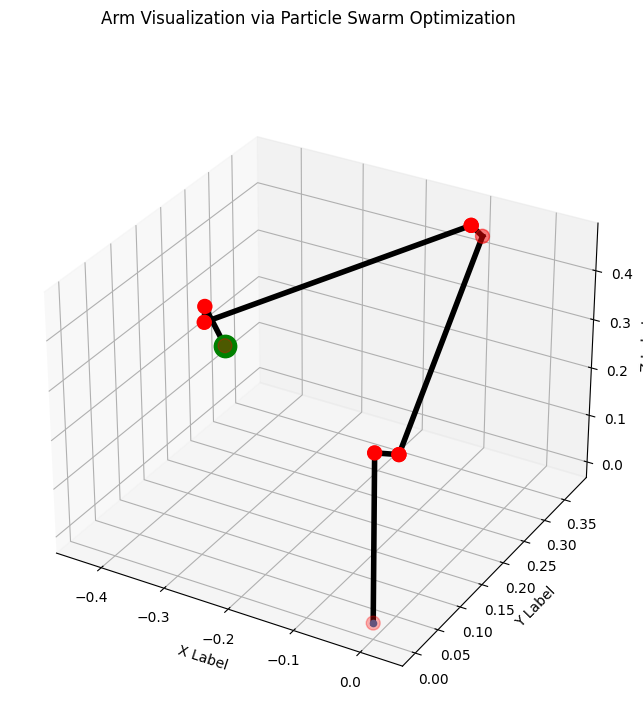

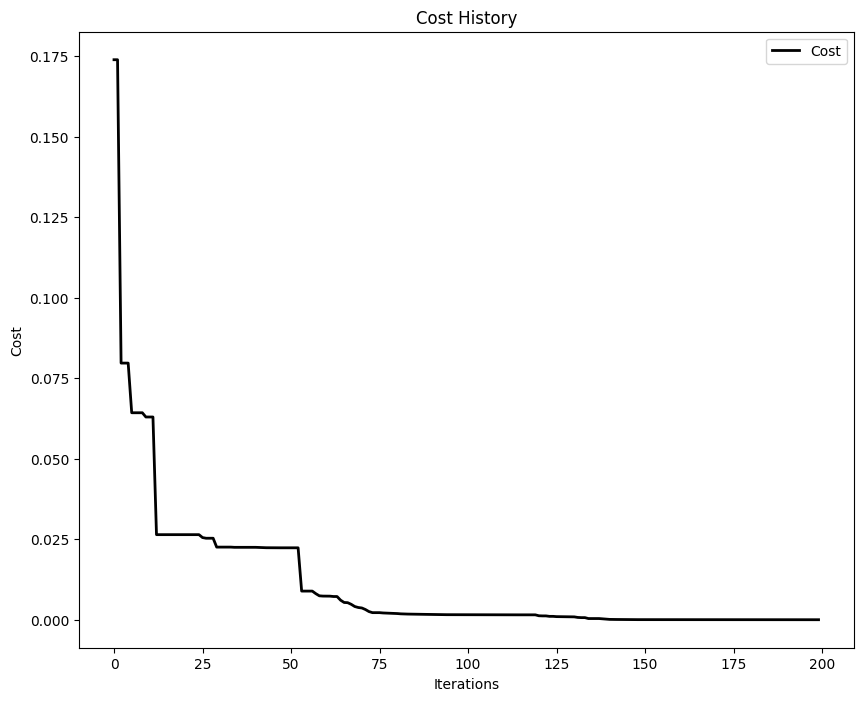

In [35]:
# Import PySwarms
import pyswarms as ps
from pyswarms.utils.functions import single_obj as fx
from pyswarms.utils.plotters import (plot_cost_history, plot_contour, plot_surface)
%load_ext autoreload
%autoreload 2

#target = np.array([-0.2, 0.2, 1.2])
# Target position and orientation     #target_position = np.array([-0.2, 0.4, 1.2])
# Workspace range
x, y, z = np.random.uniform(-0.5,0.5), np.random.uniform(-0.5,0.5), np.random.uniform(-0.15,0.2)
target_position = np.array([x,y,z])


# Call an instance of PSO
optimizer = ps.single.GlobalBestPSO(n_particles=swarm_size,
                                    dimensions=dim,
                                    options=options,
                                    bounds=constraints)

# Perform optimization
cost, joint_vars = optimizer.optimize(opt_func, iters=200)

print(f"joint_vars: \n{joint_vars}")
print(f"\nEnd position for joint_vars: \n{get_end_tip_position(joint_vars)}\n")

visualize_config(joint_vars, target_position, 'Particle Swarm Optimization')
plot_cost_history(cost_history=optimizer.cost_history)
plt.show()